# ML for Gas Adsorption

## -1. Only if you run this notebook on Colab

If you use this notebook on Colab, please uncomment the lines below (remove the `#`) and execute the cell.

In [1]:
#import sys
#!{sys.executable} -m pip install -U pandas-profiling[notebook]
#!jupyter nbextension enable --py widgetsnbextension
#!pip install --upgrade pandas sklearn holoviews bokeh plotly matplotlib
#!wget https://raw.githubusercontent.com/kjappelbaum/ml_molsim/2022/descriptornames.py
#!mkdir data
#!cd data && wget https://github.com/kjappelbaum/ml_molsim/raw/2022/data/data.csv
#!cd data && wget https://github.com/kjappelbaum/ml_molsim/raw/2022/data/features.csv
# import os, holoviews as hv
# os.environ['HV_DOC_HTML'] = 'true'

## Import packages we will need

In [2]:
# basics
import os
import numpy as np
import pprint as pp

# pandas is used to read/process data
import pandas as pd

# machine learning dependencies
# scaling of data
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
# train/test split
from sklearn.model_selection import train_test_split
# model selection
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
# the KRR model
from sklearn.kernel_ridge import KernelRidge
# linear model
from sklearn.linear_model import LinearRegression
# pipeline to streamline modeling pipelines
from sklearn.pipeline import Pipeline
# principal component analysis
from sklearn.decomposition import PCA
# polynomial kernel
from sklearn.metrics.pairwise import polynomial_kernel
# Dummy model as baseline
from sklearn.dummy import DummyClassifier, DummyRegressor
# Variance Threshold for feature selection
from sklearn.feature_selection import VarianceThreshold, SelectFromModel
# metrics to measure model performance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             mean_absolute_error, mean_squared_error, max_error)

# save/load models
import joblib

# For the permutation importance implementation
from joblib import Parallel
from joblib import delayed
from sklearn.metrics import check_scoring
from sklearn.utils import Bunch
from sklearn.utils import check_random_state
from sklearn.utils import check_array

# plotting
import matplotlib.pyplot as plt
%matplotlib inline
from pymatviz.scatter import density_scatter_with_hist as hist_density


RANDOM_SEED = 4242424242
DATA_DIR = 'data'
DATA_FILE = os.path.join(DATA_DIR, 'data.csv')

np.random.seed(RANDOM_SEED)


In [3]:

other_descriptors = ["CellV [A^3]"]

geometric_descriptors = [
    "Di",
    "Df",
    "Dif",
    "density [g/cm^3]",
    "total_SA_volumetric",
    "total_SA_gravimetric",
    "total_POV_volumetric",
    "total_POV_gravimetric",
]

linker_descriptors = [
    "f-lig-chi-0",
    "f-lig-chi-1",
    "f-lig-chi-2",
    "f-lig-chi-3",
    "f-lig-Z-0",
    "f-lig-Z-1",
    "f-lig-Z-2",
    "f-lig-Z-3",
    "f-lig-I-0",
    "f-lig-I-1",
    "f-lig-I-2",
    "f-lig-I-3",
    "f-lig-T-0",
    "f-lig-T-1",
    "f-lig-T-2",
    "f-lig-T-3",
    "f-lig-S-0",
    "f-lig-S-1",
    "f-lig-S-2",
    "f-lig-S-3",
    "lc-chi-0-all",
    "lc-chi-1-all",
    "lc-chi-2-all",
    "lc-chi-3-all",
    "lc-Z-0-all",
    "lc-Z-1-all",
    "lc-Z-2-all",
    "lc-Z-3-all",
    "lc-I-0-all",
    "lc-I-1-all",
    "lc-I-2-all",
    "lc-I-3-all",
    "lc-T-0-all",
    "lc-T-1-all",
    "lc-T-2-all",
    "lc-T-3-all",
    "lc-S-0-all",
    "lc-S-1-all",
    "lc-S-2-all",
    "lc-S-3-all",
    "lc-alpha-0-all",
    "lc-alpha-1-all",
    "lc-alpha-2-all",
    "lc-alpha-3-all",
    "D_lc-chi-0-all",
    "D_lc-chi-1-all",
    "D_lc-chi-2-all",
    "D_lc-chi-3-all",
    "D_lc-Z-0-all",
    "D_lc-Z-1-all",
    "D_lc-Z-2-all",
    "D_lc-Z-3-all",
    "D_lc-I-0-all",
    "D_lc-I-1-all",
    "D_lc-I-2-all",
    "D_lc-I-3-all",
    "D_lc-T-0-all",
    "D_lc-T-1-all",
    "D_lc-T-2-all",
    "D_lc-T-3-all",
    "D_lc-S-0-all",
    "D_lc-S-1-all",
    "D_lc-S-2-all",
    "D_lc-S-3-all",
    "D_lc-alpha-0-all",
    "D_lc-alpha-1-all",
    "D_lc-alpha-2-all",
    "D_lc-alpha-3-all",
]

metalcenter_descriptors = [
    "mc_CRY-chi-0-all",
    "mc_CRY-chi-1-all",
    "mc_CRY-chi-2-all",
    "mc_CRY-chi-3-all",
    "mc_CRY-Z-0-all",
    "mc_CRY-Z-1-all",
    "mc_CRY-Z-2-all",
    "mc_CRY-Z-3-all",
    "mc_CRY-I-0-all",
    "mc_CRY-I-1-all",
    "mc_CRY-I-2-all",
    "mc_CRY-I-3-all",
    "mc_CRY-T-0-all",
    "mc_CRY-T-1-all",
    "mc_CRY-T-2-all",
    "mc_CRY-T-3-all",
    "mc_CRY-S-0-all",
    "mc_CRY-S-1-all",
    "mc_CRY-S-2-all",
    "mc_CRY-S-3-all",
    "D_mc_CRY-chi-0-all",
    "D_mc_CRY-chi-1-all",
    "D_mc_CRY-chi-2-all",
    "D_mc_CRY-chi-3-all",
    "D_mc_CRY-Z-0-all",
    "D_mc_CRY-Z-1-all",
    "D_mc_CRY-Z-2-all",
    "D_mc_CRY-Z-3-all",
    "D_mc_CRY-I-0-all",
    "D_mc_CRY-I-1-all",
    "D_mc_CRY-I-2-all",
    "D_mc_CRY-I-3-all",
    "D_mc_CRY-T-0-all",
    "D_mc_CRY-T-1-all",
    "D_mc_CRY-T-2-all",
    "D_mc_CRY-T-3-all",
    "D_mc_CRY-S-0-all",
    "D_mc_CRY-S-1-all",
    "D_mc_CRY-S-2-all",
    "D_mc_CRY-S-3-all",
]

functionalgroup_descriptors = [
    "func-chi-0-all",
    "func-chi-1-all",
    "func-chi-2-all",
    "func-chi-3-all",
    "func-Z-0-all",
    "func-Z-1-all",
    "func-Z-2-all",
    "func-Z-3-all",
    "func-I-0-all",
    "func-I-1-all",
    "func-I-2-all",
    "func-I-3-all",
    "func-T-0-all",
    "func-T-1-all",
    "func-T-2-all",
    "func-T-3-all",
    "func-S-0-all",
    "func-S-1-all",
    "func-S-2-all",
    "func-S-3-all",
    "func-alpha-0-all",
    "func-alpha-1-all",
    "func-alpha-2-all",
    "func-alpha-3-all",
    "D_func-chi-0-all",
    "D_func-chi-1-all",
    "D_func-chi-2-all",
    "D_func-chi-3-all",
    "D_func-Z-0-all",
    "D_func-Z-1-all",
    "D_func-Z-2-all",
    "D_func-Z-3-all",
    "D_func-I-0-all",
    "D_func-I-1-all",
    "D_func-I-2-all",
    "D_func-I-3-all",
    "D_func-T-0-all",
    "D_func-T-1-all",
    "D_func-T-2-all",
    "D_func-T-3-all",
    "D_func-S-0-all",
    "D_func-S-1-all",
    "D_func-S-2-all",
    "D_func-S-3-all",
    "D_func-alpha-0-all",
    "D_func-alpha-1-all",
    "D_func-alpha-2-all",
    "D_func-alpha-3-all",
]


summed_linker_descriptors = [
    "sum-f-lig-chi-0",
    "sum-f-lig-chi-1",
    "sum-f-lig-chi-2",
    "sum-f-lig-chi-3",
    "sum-f-lig-Z-0",
    "sum-f-lig-Z-1",
    "sum-f-lig-Z-2",
    "sum-f-lig-Z-3",
    "sum-f-lig-I-0",
    "sum-f-lig-I-1",
    "sum-f-lig-I-2",
    "sum-f-lig-I-3",
    "sum-f-lig-T-0",
    "sum-f-lig-T-1",
    "sum-f-lig-T-2",
    "sum-f-lig-T-3",
    "sum-f-lig-S-0",
    "sum-f-lig-S-1",
    "sum-f-lig-S-2",
    "sum-f-lig-S-3",
    "sum-lc-chi-0-all",
    "sum-lc-chi-1-all",
    "sum-lc-chi-2-all",
    "sum-lc-chi-3-all",
    "sum-lc-Z-0-all",
    "sum-lc-Z-1-all",
    "sum-lc-Z-2-all",
    "sum-lc-Z-3-all",
    "sum-lc-I-0-all",
    "sum-lc-I-1-all",
    "sum-lc-I-2-all",
    "sum-lc-I-3-all",
    "sum-lc-T-0-all",
    "sum-lc-T-1-all",
    "sum-lc-T-2-all",
    "sum-lc-T-3-all",
    "sum-lc-S-0-all",
    "sum-lc-S-1-all",
    "sum-lc-S-2-all",
    "sum-lc-S-3-all",
    "sum-lc-alpha-0-all",
    "sum-lc-alpha-1-all",
    "sum-lc-alpha-2-all",
    "sum-lc-alpha-3-all",
    "sum-D_lc-chi-0-all",
    "sum-D_lc-chi-1-all",
    "sum-D_lc-chi-2-all",
    "sum-D_lc-chi-3-all",
    "sum-D_lc-Z-0-all",
    "sum-D_lc-Z-1-all",
    "sum-D_lc-Z-2-all",
    "sum-D_lc-Z-3-all",
    "sum-D_lc-I-0-all",
    "sum-D_lc-I-1-all",
    "sum-D_lc-I-2-all",
    "sum-D_lc-I-3-all",
    "sum-D_lc-T-0-all",
    "sum-D_lc-T-1-all",
    "sum-D_lc-T-2-all",
    "sum-D_lc-T-3-all",
    "sum-D_lc-S-0-all",
    "sum-D_lc-S-1-all",
    "sum-D_lc-S-2-all",
    "sum-D_lc-S-3-all",
    "sum-D_lc-alpha-0-all",
    "sum-D_lc-alpha-1-all",
    "sum-D_lc-alpha-2-all",
    "sum-D_lc-alpha-3-all",
]

summed_metalcenter_descriptors = [
    "sum-mc_CRY-chi-0-all",
    "sum-mc_CRY-chi-1-all",
    "sum-mc_CRY-chi-2-all",
    "sum-mc_CRY-chi-3-all",
    "sum-mc_CRY-Z-0-all",
    "sum-mc_CRY-Z-1-all",
    "sum-mc_CRY-Z-2-all",
    "sum-mc_CRY-Z-3-all",
    "sum-mc_CRY-I-0-all",
    "sum-mc_CRY-I-1-all",
    "sum-mc_CRY-I-2-all",
    "sum-mc_CRY-I-3-all",
    "sum-mc_CRY-T-0-all",
    "sum-mc_CRY-T-1-all",
    "sum-mc_CRY-T-2-all",
    "sum-mc_CRY-T-3-all",
    "sum-mc_CRY-S-0-all",
    "sum-mc_CRY-S-1-all",
    "sum-mc_CRY-S-2-all",
    "sum-mc_CRY-S-3-all",
    "sum-D_mc_CRY-chi-0-all",
    "sum-D_mc_CRY-chi-1-all",
    "sum-D_mc_CRY-chi-2-all",
    "sum-D_mc_CRY-chi-3-all",
    "sum-D_mc_CRY-Z-0-all",
    "sum-D_mc_CRY-Z-1-all",
    "sum-D_mc_CRY-Z-2-all",
    "sum-D_mc_CRY-Z-3-all",
    "sum-D_mc_CRY-I-0-all",
    "sum-D_mc_CRY-I-1-all",
    "sum-D_mc_CRY-I-2-all",
    "sum-D_mc_CRY-I-3-all",
    "sum-D_mc_CRY-T-0-all",
    "sum-D_mc_CRY-T-1-all",
    "sum-D_mc_CRY-T-2-all",
    "sum-D_mc_CRY-T-3-all",
    "sum-D_mc_CRY-S-0-all",
    "sum-D_mc_CRY-S-1-all",
    "sum-D_mc_CRY-S-2-all",
    "sum-D_mc_CRY-S-3-all",
]

summed_functionalgroup_descriptors = [
    "sum-func-chi-0-all",
    "sum-func-chi-1-all",
    "sum-func-chi-2-all",
    "sum-func-chi-3-all",
    "sum-func-Z-0-all",
    "sum-func-Z-1-all",
    "sum-func-Z-2-all",
    "sum-func-Z-3-all",
    "sum-func-I-0-all",
    "sum-func-I-1-all",
    "sum-func-I-2-all",
    "sum-func-I-3-all",
    "sum-func-T-0-all",
    "sum-func-T-1-all",
    "sum-func-T-2-all",
    "sum-func-T-3-all",
    "sum-func-S-0-all",
    "sum-func-S-1-all",
    "sum-func-S-2-all",
    "sum-func-S-3-all",
    "sum-func-alpha-0-all",
    "sum-func-alpha-1-all",
    "sum-func-alpha-2-all",
    "sum-func-alpha-3-all",
    "sum-D_func-chi-0-all",
    "sum-D_func-chi-1-all",
    "sum-D_func-chi-2-all",
    "sum-D_func-chi-3-all",
    "sum-D_func-Z-0-all",
    "sum-D_func-Z-1-all",
    "sum-D_func-Z-2-all",
    "sum-D_func-Z-3-all",
    "sum-D_func-I-0-all",
    "sum-D_func-I-1-all",
    "sum-D_func-I-2-all",
    "sum-D_func-I-3-all",
    "sum-D_func-T-0-all",
    "sum-D_func-T-1-all",
    "sum-D_func-T-2-all",
    "sum-D_func-T-3-all",
    "sum-D_func-S-0-all",
    "sum-D_func-S-1-all",
    "sum-D_func-S-2-all",
    "sum-D_func-S-3-all",
    "sum-D_func-alpha-0-all",
    "sum-D_func-alpha-1-all",
    "sum-D_func-alpha-2-all",
    "sum-D_func-alpha-3-all",
]


 $\color{DarkBlue}{\textsf{Short question}}$
- We declared a global variable to fix the random seed (`RANDOM_SEED`). Why did we do this?

 1.1) Fixing `RANDOM_SEED` makes the notebook reproducible. The randomness is fixed to get the same values when we run the notebook again.

## Hands-on Project: Carbon-dioxide uptake in MOFs

In this exercise we will build a model that can predict the CO$_2$ uptake of metal-organic frameworks (MOFs), which are crystalline materials consisting of inorganic metal nodes linked by organic linkers.

![MOF building principle](assets/mof_building_principle.png)

There are two main **learning goals** for this exercise: 

1. Understand the typical workflow for machine learning in materials science. We will cover exploratory data analysis (EDA) and supervised learning (KRR).

2. Get familiar with some Python packages that are useful for data analysis and visualization. 

At the end of the exercise, you will produce an interactive plot like the one below, comparing the predictions of your model against CO$_2$ computed with GCMC simulations.
The histograms show the distributions of the errors on the training set (left) and on the test set (right).



<img src="assets/result.gif" alt="Parity interactive" width="700"/>

This exercise requires a basic knowledge of Python, e.g. that you can write list comprehensions, and are able to read documentation of functions provided by Python packages.
You will be asked to provide some function arguments (indicated by `#fillme` comments).

You can execute all the following code cells by pressing SHIFT and ENTER and get informations about the functions by pressing TAB when you are between the parentheses (see the notes for more tips). 

Also the [sklearn documentation](https://scikit-learn.org/stable/user_guide.html) is a great source of reference with many explanations and examples.

In pandas dataframe (df) you can select columns using their name by running `df[columnname]`. If at any point you think that the dataset is too large for your computer, you can select a subset using `df.sample()` or by making the test set larger in the train/test split (section 2). 

## 1. Import the data

In [4]:
df = pd.read_csv(DATA_FILE)

Let's take a look at the first few rows to see if everythings seems reasonable ...

In [5]:
df.head()

,ASA [m^2/cm^3],CellV [A^3],Df,Di,Dif,NASA [m^2/cm^3],POAV [cm^3/g],POAVF,PONAV [cm^3/g],PONAVF,...,pure_methane_widomHOA,pure_uptake_CO2_298.00_15000,pure_uptake_CO2_298.00_1600000,pure_uptake_methane_298.00_580000,pure_uptake_methane_298.00_6500000,logKH_CO2,logKH_CH4,CH4DC,CH4HPSTP,CH4LPSTP
0,2329.01,1251.28,6.61256,8.87694,8.48668,0.0,0.818919,0.68874,0.0,0.0,...,-8.144317,0.111981,14.218595,1.680640,9.163066,-5.125451,-5.511444,175.569974,215.005044,39.435070
1,1983.81,1254.01,5.80566,7.13426,7.13154,0.0,0.495493,0.58032,0.0,0.0,...,-10.208005,0.481625,9.312424,1.513152,5.908356,-4.502967,-5.505947,143.616349,193.059644,49.443295
2,2259.13,1250.58,5.99131,8.01682,7.98933,0.0,0.728036,0.65710,0.0,0.0,...,-8.479801,0.401683,14.796071,1.569714,7.933198,-4.433968,-5.525707,160.238808,199.765744,39.526937
3,1424.54,1249.27,4.73477,7.05822,7.05822,0.0,0.453157,0.47338,0.0,0.0,...,-12.615382,0.821747,10.816880,2.161833,6.710778,-4.135434,-5.297082,132.576623,195.582107,63.005483
4,2228.31,1250.61,6.40783,8.35944,8.26946,0.0,0.700539,0.65092,0.0,0.0,...,-8.743404,0.258905,14.153999,1.653013,8.272621,-4.774301,-5.515219,171.601539,214.452966,42.851427


<details>
<summary> <font color='green'>Click here for a hint</font></summary>
<ul>
    <li>Use something like <code>pd.options.display.max_columns=100</code> to adjust how many columns are shown.<code>pd.options.display.max_columns=100</code>  would show at maximum 100 columns. </li>
</ul>
</details>

Let's also get some basic information ...

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Columns: 343 entries, ASA [m^2/cm^3] to CH4LPSTP
dtypes: float64(342), str(1)
memory usage: 45.5 MB


 $\color{DarkBlue}{\textsf{Short question}}$
- How many materials are in the dataset? 
- Which datatypes do we deal with?

2.1) 17,379 materials

2.2) 343 columns in total:
342 are `float64` and 1 is a `str`

Below, we define three global variables (hence upper case), which are the *names* of our feature and target columns. We will use the `TARGET` for the actual regression and the `TARGET_BINARY` only for the stratified train/test split. The `FEATURES` variable is a list of column names of our dataframe.

In [5]:
TARGET = "pure_uptake_CO2_298.00_1600000"
TARGET_BINARY = "target_binned"  # will be created later
FEATURES = (
    geometric_descriptors
    + summed_functionalgroup_descriptors
    + summed_linker_descriptors
    + summed_metalcenter_descriptors
)


As descriptors we will use geometric properties such as density, pore volume, etc. and [revised autocorrelation functions](https://pubs.acs.org/doi/abs/10.1021/acs.jpca.7b08750) (RACs) that have been optimized for describing inorganic compounds ([and recently adapated for MOFs](https://www.nature.com/articles/s41467-020-17755-8))

Examples for pore geometry descriptors (in `geometric_descriptors`) include: $D_i$ (the size of the largest included sphere), $D_f$ (the largest free sphere), and $D_{if}$ (the largest included free sphere) along the pore $-$ three ways of characterizing pore size. 

![pore diameters](assets/spheres.png)

Also included are the surface area (SA) of the pore, and the probe-occupiable pore volume (POV).
More details on the description of pore geometries can be found in [Ongari et al.](https://pubs.acs.org/doi/abs/10.1021/acs.langmuir.7b01682)

RACs (in the lists starting with `summed_...`) operate on the structure graph and encode information about the metal center, linkers and the functional groups as differences or products of heuristics that are relevant for inorganic chemistry, such as electronegativity ($\chi$), connectivity ($T$), identity ($I$), covalent radii ($S$), and nuclear charge ($Z$).


<img src="assets/racs.png" alt="RACs scheme from the lecture" width="700"/>

The number in the descriptornames shows the coordination shell that was considered in the calculation of the RACs.

The target we use for this application is the high-pressure CO$_2$ uptake. This is the amount of CO$_2$ (mmol) the MOF can load per gram.

## 2. Split the data

Next, we split our data into a training set and a test set.

In order to prevent *any* information of the test set from leaking into our model, we split *before* starting to analyze or transform our data. For more details on why this matters, see [chapter 7.10.2 of Elements of Statistical Learning](https://web.stanford.edu/~hastie/ElemStatLearn//printings/ESLII_print10.pdf).

### 2.1. Split with stratification

[Stratification](https://en.wikipedia.org/wiki/Stratified_sampling) ensures that the class distributions (ratio of "good" to "bad" materials) are the same in the training and test set.

 $\color{DarkBlue}{\textsf{Short question}}$

- Why is this important? What could happen if we would not do this? 

3.1) Stratification keeps the ratio of "good" and "bad" materials the same in the training set. Without it, a purely random split can by chance put too few "good" materials in the test set or in the training set. The test score would then be noisy and unrepresentative, since it would say little about how well the model handles the "good" materials. The model could also learn that region poorly, and results from different splits would be hard to compare. With stratification, the test set is a representative sample of the whole dataset, so the test error is a more reliable estimate of generalisation.

For stratification to work, we to define what makes a "good" or a "bad" material. We will use 15 mmol CO$_2$ / g as the threshold for the uptake, thus binarizing our continuous target variable. (You can choose it based on the histogram of the variables).

 $\color{DarkBlue}{\textsf{Short Exercise}}$
 - add a column 'target_binary' that encodes whether a material is low performing (`0`) or high perfoming (`1`) by comparing the uptake with the `THRESHOLD`

<details>
<summary> <font color='green'>Click here for a hint</font></summary>
<ul>
    <li> you can use <a href='https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.cut.html'>pd.cut</a>, 
    <a href='https://stackoverflow.com/questions/4406389/if-else-in-a-list-comprehension'>list comprehension</a>, the <a href='https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.Binarizer.html#sklearn.preprocessing.Binarizer'> binarizer in sklearn </a>...) </li>
    <li> a list comprehension example: <code> [1 if value > THRESHOLD else 0 for value in df[TARGET]] </code> </li>
</ul>
</details>

In [6]:
THRESHOLD = 15 # in units of mmol CO2/g
df[TARGET_BINARY] = [1 if value > THRESHOLD else 0 for value in df[TARGET]]

In [9]:
df[TARGET_BINARY].value_counts(normalize=True)

target_binned
0    0.65723
1    0.34277
Name: proportion, dtype: float64

Now, we can perform the actual split into training and test set.

 $\color{DarkBlue}{\textsf{Short Exercise}}$
- select reasonable values for `XX` and `XY` and then perform the test/train splits. What do you consider when making this decision (think about what you would do with really small and really big datasets, what happens if you have only one test point, what happens to the model performance if you have more test points than training points)? 
- why do we need to perform the split into a training and test set? 
- would we use the test set to tune the hyperparameters of our model?

<details>
<summary> <font color='green'>Click here for a hint</font></summary>
<ul>
    <li>The `size` arguments can either be integers or, often more convenient, decimals like 0.1</li>
    <li>When you perform the split into training and test set you need to trade-off bias (pessimistic bias due to little training data) and variance (due to little test data) </li>
    <li>A typical split cloud be 70/30, but for huge dataset the test set might be too big and for small datasets the training set might be too small in this way </li>
</ul>
</details>

5.1) Training set/test set ratio is selected keeping in mind two factors, namely bias and variance. If the training set is too small, the model has less data to learn from, so the measured performance is pessimistically biased. If the test set is too small, the test error has high variance and depends heavily on which few points happened to be picked. With only one test point, the score would be essentially random and meaningless. If there are more test points than training points, the model is trained on too little data and performs worse than it could.

5.2) We want to train the model to 'learn' the properties, and see if it can predict the properties of the test set, which is the unseen new data. A model can fit the training data almost perfectly (overfitting) and still predict poorly on new data. The test set is held out and never used in training (no information leakage ensured by the splitting), so its error is an unbiased estimate of performance on new data.

5.3) No. If we choose hyperparameters based on the test score, the test set is no longer independent: information from it leaks into the model, and the reported test performance becomes optimistic. Hyperparameters should be tuned on the training data only and the test set is then used once at the end for the final evaluation.

In [7]:
df_train_stratified, df_test_stratified = train_test_split(
    df,
    train_size=0.7,
    test_size=0.3,
    random_state=RANDOM_SEED,
    stratify=df[TARGET_BINARY],
)


In [11]:
print(len(df_train_stratified), len(df_test_stratified))
print(df_train_stratified[TARGET_BINARY].mean(), df_test_stratified[TARGET_BINARY].mean())

12165 5214
0.34278668310727495 0.3427311085538934


## 3. Exploratory data analysis (EDA) 

After we have put the test set aside, we can give the training set a closer look.

### 3.1. Correlations

 $\color{DarkBlue}{\textsf{Short Exercise}}$
- Plot some features against the target property and calculate the Pearson and Spearman correlation coefficient (what is the different between those correlation coefficients?) 
- What are the strongest correlations? Did you expect them? 
- What can be a problem when features are correlated?
- *Optional:* Do they change if you switch from CO$_2$ to CH$_4$ uptake as the target instead? Explain your observation.

To get the correlation matrices, you can use the `df.corr(method=)`method on your dataframe (`df`). You might want to calculate not the full correlation matrix but just the correlation of the features with the targets

<details>
<summary> <font color='green'>Click here for a hint</font></summary>
<ul>
    <li> To get the correlation with a target, you can use indexing. E.g. <code>df.corr(method='spearman')[TARGET]</code></li>
    <li> use <code>.sort_values()</code> method on the output of `df.corr()` to sort by the value of the correlation coefficient  </li>
      <li> You can use something like <code>scatter = hv.Scatter(df, 'Di', [TARGET,  'density [g/cm^3]']).opts(color='density [g/cm^3]', cmap='rainbow')</code> for plotting. Also consider the <a href="https://holoviews.org/reference/elements/matplotlib/Scatter.html"> <code>holoviews</code> documentation</a>. In case <code>holoviews</code> is too new for you, you can of course just use <code>matplotlib</code> and something like <code>plt.scatter(x,y)</code> </li>
</ul>
</details>

In [12]:
train_eda = df_train_stratified[FEATURES + [TARGET]]

corr_pearson = train_eda.corr(method="pearson")[TARGET].drop(TARGET)
corr_spearman = train_eda.corr(method="spearman")[TARGET].drop(TARGET)

corr_table = pd.DataFrame({"pearson": corr_pearson, "spearman": corr_spearman})
corr_table = corr_table.reindex(
    corr_table["spearman"].abs().sort_values(ascending=False).index
)
corr_table.head(10)

,pearson,spearman
total_POV_gravimetric,0.780957,0.957266
total_SA_gravimetric,0.926889,0.954318
density [g/cm^3],-0.884084,-0.949026
total_POV_volumetric,0.917005,0.940868
total_SA_volumetric,0.848716,0.883667
Di,0.760534,0.849900
Dif,0.760671,0.849870
Df,0.767486,0.844760
sum-D_mc_CRY-T-2-all,-0.375067,-0.418358
sum-mc_CRY-T-1-all,-0.233439,-0.270755


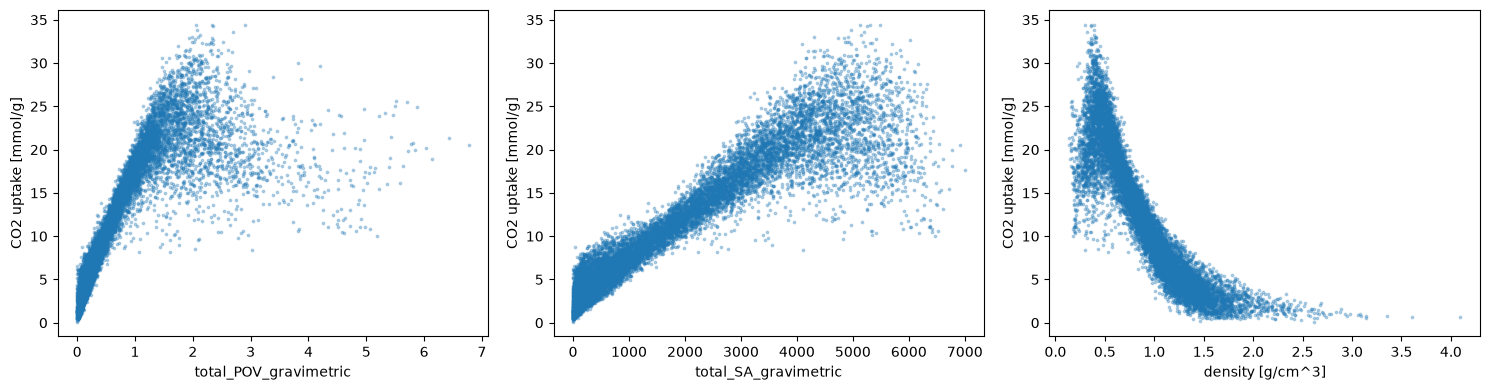

In [13]:
top_features = corr_table.index[:3]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, top_features):
    ax.scatter(df_train_stratified[feature], df_train_stratified[TARGET], s=3, alpha=0.3)
    ax.set_xlabel(feature)
    ax.set_ylabel("CO2 uptake [mmol/g]")
plt.tight_layout()
plt.show()

In [14]:
def corr_with_target(target):
    sub = df_train_stratified[FEATURES + [target]]
    table = pd.DataFrame({
        "pearson": sub.corr(method="pearson")[target].drop(target),
        "spearman": sub.corr(method="spearman")[target].drop(target),
    })
    return table.reindex(table["spearman"].abs().sort_values(ascending=False).index)

corr_ch4_low = corr_with_target("pure_uptake_methane_298.00_580000")
corr_ch4_high = corr_with_target("pure_uptake_methane_298.00_6500000")

display(corr_ch4_low.head(8))
display(corr_ch4_high.head(8))

,pearson,spearman
sum-func-Z-1-all,-0.353605,-0.484986
sum-func-alpha-0-all,-0.268920,-0.469243
sum-func-Z-2-all,-0.292104,-0.446545
sum-func-Z-0-all,-0.243085,-0.440613
sum-f-lig-Z-0,-0.300532,-0.436958
sum-func-alpha-1-all,-0.329344,-0.429989
sum-func-alpha-3-all,-0.294959,-0.425455
sum-func-alpha-2-all,-0.300549,-0.413381


,pearson,spearman
total_POV_gravimetric,0.925595,0.976635
density [g/cm^3],-0.909069,-0.974788
total_SA_gravimetric,0.973461,0.970079
total_POV_volumetric,0.924322,0.954679
Df,0.843787,0.855388
Dif,0.843029,0.853283
Di,0.842689,0.852752
total_SA_volumetric,0.767577,0.841022


*3.1)* Pearson measures how well the relationship is described by a straight line. Spearman is the Pearson coefficient of the ranks, so it only needs a monotonic relationship and is less sensitive to curvature, skewed distributions and outliers. Where Spearman is clearly larger than Pearson (e.g. pore volume), the relationship is monotonic but nonlinear.

*3.2)* Strongest correlations, all with geometric descriptors:
- gravimetric pore volume and surface area: positive
- density: negative

Yes, expected. At high pressure the uptake is limited by the accessible pore volume per gram, and a higher density means less empty space per gram. Gravimetric descriptors correlate better than volumetric ones because the target is in mmol/g. The pore volume scales with $r^3$ and the surface area with $r^2$, so the pore volume depends more steeply on the pore size. The RACs correlate only weakly, because at high pressure geometry dominates over chemistry.

*3.3)* Correlated features (e.g. density, pore volume, surface area) carry redundant information. This inflates the dimensionality, makes linear-model coefficients unstable, and splits or masks feature importances. High correlation with the target also does not imply causation.

*3.4) Optional (CH$_4$):*
- High pressure (65 bar): same picture as CO$_2$. Geometric descriptors dominate ($|\rho_S| \approx 0.97$), RACs are weak.
- Low pressure (5.8 bar): geometric correlations drop ($|\rho_S| \approx 0.4$), and functional-group RACs become the strongest ($|\rho_S| \approx 0.5$).
- Reason: at high pressure the pores approach saturation, so the pore volume limits the uptake. At low pressure (Henry regime), the binding strength between framework and gas matters, which depends on the chemistry.

## 4. Baselines

For machine learning, it is important to have some *baselines* to which one then compares the results of a model. Think of a classification model for some rare disease where we only have 1% postives. A classification model that only predictes the negatives *all the time* will still have a amazingly high accuracy. To be able to understand if our model is really better than such a simple prediction we need to make the simple prediction first. This is what we call a baseline.

A baseline could be a really simple model, a basic heuristic or the current state of the art.
this. We will use a heuristic.

For this we use sklearn `Dummy` objects that simply calculate the mean, the median or the most frequent case of the training set, when you run the `fit()` method on them (which takes the features matrix $\mathbf{X}$ and the labels $\mathbf{y}$ as arguments.
This is, the prediction of a `DummyRegressor` with `mean` strategy will always be the mean, independent of the input (it will not look at the feature matrix!). 

Instead of using those `sklearn` objects you could also just manually compute the the mean or median of the dataset. But we will use those objects as we can learn in this way how to use estimators in `sklearn` and it is also allows you to test your full pipeline with different (baseline) models. 
What does this mean? In practice this means that you can use all the regression and classification models shown in the figure below in the same way, they will all have a `fit()` method that accepts `X` and `y` and a predict method that accepts `X` and returns the predictions. 


<img src="https://scikit-learn.org/1.3/_static/ml_map.png" alt="ML Map" width="800"/>

The estimator objects can be always used in the same way 

<img src="https://static.packt-cdn.com/products/9781789800265/graphics/d49a2e95-8f22-42ed-89f1-474b3d028787.png" alt="ML Map" width="400"/>

Using these objects, instead of the mean directly, allows you to easily swap them with other models in pipelines, where one chains many data transformation steps (see section 6).

### 4.1. Build dummy models

$\color{DarkBlue}{\textsf{Short Question}}$
- If you call `.fit(X, y)` on a `DummyRegressor` does it actually use the `X`? If not, why is there still the place for the `X` in the function? If yes, how does it use it?

$\color{DarkBlue}{\textsf{Short Exercise}}$
- Create [`DummyRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html) instances for  `mean`, `median`. (e.g. `dummyinstance = DummyRegressor(strategy='mean')`)
- Train them on the training data (`dummyinstance.fit(df_train[FEATURES], df_train[TARGET])`)

<details>
<summary> <font color='green'>Click here for hints</font></summary>
<ul>
    <li> to create <code>DummyRegressor</code> you can for example use <code> dummyregressor_mean = DummyRegressor(strategy='mean') </code> </li>
    <li> to see the implementation of the <code>DummyRegressor</code> you can check out <a href="https://github.com/scikit-learn/scikit-learn/blob/73732e5a0bc9b72c7049dc699d69aaedbb70ef0a/sklearn/dummy.py#L391"> the source code on GitHub</a> </li>
</ul>
</details>

In [15]:
# Build DummyRegressors
dummyregressor_mean = DummyRegressor(strategy='mean')
dummyregressor_median = DummyRegressor(strategy='median')

In [16]:
# Fit Dummy Regressors
dummyregressor_mean.fit(df_train_stratified[FEATURES], df_train_stratified[TARGET])
dummyregressor_median.fit(df_train_stratified[FEATURES], df_train_stratified[TARGET])

,"strategy strategy: {""mean"", ""median"", ""quantile"", ""constant""}, default=""mean""Strategy to use to generate predictions.* ""mean"": always predicts the mean of the training set* ""median"": always predicts the median of the training set* ""quantile"": always predicts a specified quantile of the training set, provided with the quantile parameter.* ""constant"": always predicts a constant value that is provided by the user.",'median'
,"constant constant: int or float or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
,"quantile quantile: float in [0.0, 1.0], default=NoneThe quantile to predict using the ""quantile"" strategy. A quantile of0.5 corresponds to the median, while 0.0 to the minimum and 1.0 to themaximum.",None
Name,Type,Value
"constant_ constant_: ndarray of shape (1, n_outputs)Mean or median or quantile of the training targets or constant valuegiven by the user.","ndarray[float64](1, 1)",[[10.44]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](164,)","['Di','Df','Dif',...,'sum-D_mc_CRY-S-1-all','sum-D_mc_CRY-S-2-all', 'sum-D_mc_CRY-S-3-all']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,164
n_outputs_ n_outputs_: intNumber of outputs.,int,1


#### Evaluate the performance of the dummy models

 $\color{DarkBlue}{\textsf{Short Exercise}}$
- Calculate maximum error, mean absolute error and mean square error for the dummy regressors on training and test set. What would you expect those numbers to be?
- Do the actual values surprise you? 
- What does this mean in practice for reporting of metrics/the reasoning behind using baseline models

It can be handy to store our metrics of choice in a nested dictionary ([Python dictionaries are key-value pairs](https://www.tutorialspoint.com/python/python_dictionary.htm)): 

```python
{
    'dummyestimator1': {
                        'metric_a_key': metric_a_value, 
                        'metric_b_key': metric_b_value
                    },
    'dummyestimator2': {
                        'metric_a_key': metric_a_value, 
                        'metric_b_key': metric_b_value
                    },
 }
``` 

You will now write functions `get_regression_metrics(model, X, y_true)` that compute the metrics and return this dictionary for a given model. The `predict` method takes the feature matrix $\mathbf{X}$ as input.

In them, we calculate 

$\mathrm {MAE} =\frac{\sum _{i=1}^{n}\left|Y_{i}-\hat{y}_{i}\right|}{n}.$

and 

$\mathrm {MSE} = {\frac {1}{n}}\sum _{i=1}^{n}(Y_{i}-{\hat {Y_{i}}})^{2}.$ 

where $\hat{y}$ are the predictions and, $Y_{i}$ the true values.

as well as the maximum error.

<details>
<summary> <font color='green'>Click here for hints</font></summary>
<ul>
    <li> to perform a prediction using a estimator object, you can call <code> classifier.predict(X) </code> </li>
    <li> to calculate metrics, you can for example call <code>accuracy_score(true_values, predicted_values) </code> </li>
</ul>
</details>

In [8]:
def get_regression_metrics(model, X, y_true):
    """
    Get a dicionary with regression metrics:

    model: sklearn model with predict method
    X: feature matrix
    y_true: ground truth labels
    """
    y_predicted = model.predict(X)

    mae = mean_absolute_error(y_true, y_predicted)
    mse = mean_squared_error(y_true, y_predicted)
    maximum_error = max_error(y_true, y_predicted)

    metrics_dict = {
        'mae': mae,
        'mse': mse,
        'max_error': maximum_error
    }

    return metrics_dict

In [18]:
dummy_regressors = [
    ('mean', dummyregressor_mean),
    ('median', dummyregressor_median)
]

In [19]:
dummy_regressor_results_test = {} # initialize empty dictionary
dummy_regressor_results_train = {}

# loop over the dummy_regressor list
# if you have a tuple regressorname, regressor = (a, b) that is automatically expanded into the variables
# a = regressorname, b = regressor
for regressorname, regressor in dummy_regressors:
    print(f"Calculating metrics for {regressorname}")
    dummy_regressor_results_test[regressorname] = get_regression_metrics(
        regressor, df_test_stratified[FEATURES], df_test_stratified[TARGET]
    )
    dummy_regressor_results_train[regressorname] = get_regression_metrics(
        regressor, df_train_stratified[FEATURES], df_train_stratified[TARGET]
    )

Calculating metrics for mean
Calculating metrics for median


In [20]:
print("train"); display(pd.DataFrame(dummy_regressor_results_train))
print("test");  display(pd.DataFrame(dummy_regressor_results_test))

train


,mean,median
mae,6.332683,6.260357
mse,54.361785,56.256642
max_error,22.603803,23.980341


test


,mean,median
mae,6.273667,6.183402
mse,53.032750,54.691016
max_error,22.680388,24.056926


**4.1)** No, `fit` does not use `X` for the prediction. The `DummyRegressor` only looks at `y` and stores its mean or median as `constant_` (here 10.44 for the median); `X` is only used to record the number and names of the features (`n_features_in_`, `feature_names_in_`). `X` is still an argument so that the dummy has the same interface as every other estimator and can be swapped into pipelines, cross-validation and grid searches without changing any code.

**4.2)** Since the prediction is a constant that does not depend on the features, we expect similar errors on the training and test set (the split is stratified, so both have the same target distribution). For the mean strategy the MSE should equal the variance of the target.

**4.3)** Actual values: MAE of about 6.3 mmol/g, MSE of about 54 (train) and 53 (test), and a maximum error of about 23. The train and test values are almost identical, as expected. The mean gives the lower MSE and the median the lower MAE, because the mean minimizes the squared error and the median minimizes the absolute error. What is surprising is how large the errors are compared to the typical uptake of about 10 mmol/g.

**4.4)** A baseline shows what performance is achievable without any information from the features, so any model has to beat these numbers to be useful. A reported error, e.g. an MAE of 6 mmol/g, only has meaning when compared with such a baseline.`

## 5. Build actual regression models

Let's build a simple [kernel ridge regression (KRR)](https://emtiyaz.github.io/pcml15/kernel-ridge-regression.pdf) machine learning model and train it with our raw data.
You can try different kernels, but we recommend to start with the Gaussian radial basis function ('rbf') kernel.
 
 $\color{DarkBlue}{\textsf{Short Question}}$
- Do you expect this model to perform better than the dummy models?
- Train it and then calculate the performance metrics on the training and test set. How do they compare to the performance of the dummy models?
- What is the shape of the Kernel and of the weights? (you can check your answer by looking at the `dual_coef_` attribute of the KRR instance. You can get shapes of objects using the `shape` atrribute 

In [21]:
# Train the model with a Gaussian kernel
krr = KernelRidge(kernel='rbf')
krr.fit(df_train_stratified[FEATURES], df_train_stratified[TARGET])

,"kernel kernel: str or callable, default=""linear""Kernel mapping used internally. This parameter is directly passed to:class:`~sklearn.metrics.pairwise.pairwise_kernels`.If `kernel` is a string, it must be one of the metricsin `pairwise.PAIRWISE_KERNEL_FUNCTIONS` or ""precomputed"".If `kernel` is ""precomputed"", X is assumed to be a kernel matrix.Alternatively, if `kernel` is a callable function, it is called oneach pair of instances (rows) and the resulting value recorded. Thecallable should take two rows from X as input and return thecorresponding kernel value as a single number. This means thatcallables from :mod:`sklearn.metrics.pairwise` are not allowed, asthey operate on matrices, not single samples. Use the stringidentifying the kernel instead.",'rbf'
,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Regularization strength; must be a positive float. Regularizationimproves the conditioning of the problem and reduces the variance ofthe estimates. Larger values specify stronger regularization.Alpha corresponds to ``1 / (2C)`` in other linear models such as:class:`~sklearn.linear_model.LogisticRegression` or:class:`~sklearn.svm.LinearSVC`. If an array is passed, penalties areassumed to be specific to the targets. Hence they must correspond innumber. See :ref:`ridge_regression` for formula.",1
,"gamma gamma: float, default=NoneGamma parameter for the RBF, laplacian, polynomial, exponential chi2and sigmoid kernels. Interpretation of the default value is left tothe kernel; see the documentation for sklearn.metrics.pairwise.Ignored by other kernels.",None
,"degree degree: float, default=3Degree of the polynomial kernel. Ignored by other kernels.",3
,"coef0 coef0: float, default=1Zero coefficient for polynomial and sigmoid kernels.Ignored by other kernels.",1
,"kernel_params kernel_params: dict, default=NoneAdditional parameters (keyword arguments) for kernel function passedas callable object.",None
Name,Type,Value
"X_fit_ X_fit_: {ndarray, sparse matrix} of shape (n_samples, n_features)Training data, which is also required for prediction. Ifkernel == ""precomputed"" this is instead the precomputedtraining matrix, of shape (n_samples, n_samples).","ndarray[float64](12165, 164)","[[15.07,10.7 ,15.07,...,15.6 ,14.64,30.24], [11.51, 7.48,11.38,...,14.72,28.8 ,50.72], [ 6.56, 4.61, 6.56,..., 6.46, 7.32,15.76], ..., [ 5.48, 4.2 , 5.48,...,16.2 ,12. ,37.92], [13.2 , 8.9 ,13.2 ,..., 7.36,14.4 ,23.92], [ 5.06, 3.4 , 4.27,..., 5.76, 7.32,10.84]]"
"dual_coef_ dual_coef_: ndarray of shape (n_samples,) or (n_samples, n_targets)Representation of weight vector(s) in kernel space","ndarray[float64](12165,)","[ 4.85,10.53, 4.11,..., 3.57,13.45, 3.45]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](164,)","['Di','Df','Dif',...,'sum-D_mc_CRY-S-1-all','sum-D_mc_CRY-S-2-all', 'sum-D_mc_CRY-S-3-all']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,164


In [22]:
krr_train = get_regression_metrics(krr, df_train_stratified[FEATURES], df_train_stratified[TARGET])
krr_test = get_regression_metrics(krr, df_test_stratified[FEATURES], df_test_stratified[TARGET])

print("train", krr_train)
print("test", krr_test)
print("dual_coef_ shape:", krr.dual_coef_.shape)
print("training set size:", len(df_train_stratified))

train {'mae': 5.893072129435301, 'mse': 48.35125984412744, 'max_error': 17.207763399500003}
test {'mae': 11.692068235569506, 'mse': 189.9456967065597, 'max_error': 34.4921121426}
dual_coef_ shape: (12165,)
training set size: 12165


**5.1)** We would expect the KRR to be better than the dummy models, since it actually uses the features.

**5.2)** On the training set it is better (MAE 5.9 vs. 6.3, MSE 48 vs. 54). On the test set it is much **worse** than the dummy models (MAE 11.7 vs. 6.3, MSE 190 vs. 53, max. error 34.5 vs. 22.7). The reason is that the raw features are not scaled and have very different magnitudes, so the Euclidean distances in the RBF kernel $k(x, x') = \exp(-\gamma \lVert x - x' \rVert^2)$ are dominated by the large-valued features and are huge. The kernel value between two different MOFs is then practically zero, so the model cannot generalize: for an unseen MOF all kernel values are about 0 and the prediction is about 0. This is why the test MAE is about equal to the mean uptake. This is also an example of why baselines matter: without them, the test errors alone would not reveal that the model is worse than guessing the mean. It motivates scaling the features (section 7).

**5.3)** The kernel matrix is $n_\text{train} \times n_\text{train}$ = 12165 × 12165 (one entry for each pair of training points). The weights $\alpha$ (`dual_coef_`) have shape (12165,), one weight per training point.

## 6. Evaluate the model performance in detail

We have trained our first machine learning model!
We'll first have a closer look at its performance, before learning how to improve it.

 $\color{DarkBlue}{\textsf{Short Exercise}}$
- Create a parity plot (true values against predictions)for the training and test data
- Plot a histogram of the distribution of the training and test errors on the training and test set. Plot the errors also as a function of the true value
- Let's assume we would like to use our model for pre-screening a library of millions of porous materials to zoom-in on those with the most promising gas uptake. Could you tolerate the errors of your model?
- Compare the parity plots for this model with the ones for the dummy models. 
Use the plotting functions below the evaluate all the following models you train.

For this exercise, it can be handy to save the results in a dictionary, e.g. 
```(python)
res_train = {
    'y true': [],
    'y pred': []
}
```

<details>
<summary> <font color='green'>Click here for hints for plotting</font></summary>
<ul>
    <li> If you want to use matplotlib to make the parity plots, you can use the <a href="https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.hist2d.html">hist2d function</a> </li>
    <li> To create the frequencies and the edges of a histogram, one can use <code>np.histogram</code></li>
</ul>
</details>

In [23]:
# Create dictionaries with training and test results to create parity plots
res_train = {
    'y true': df_train_stratified[TARGET],
    'y pred': krr.predict(df_train_stratified[FEATURES])
}

res_test = {
    'y true': df_test_stratified[TARGET],
    'y pred': krr.predict(df_test_stratified[FEATURES])
}

Now, lets calculate the errors

In [24]:
res_train["error"] = res_train["y true"] - res_train["y pred"]
res_test["error"] = res_test["y true"] - res_test["y pred"]

Now, plot the parity plots and error distributions

<details>
<summary> <font color='green'>Click here for hints for plotting</font></summary>
If you want interactive plots, you can use the following code:
<pre><code>
hv.extension("bokeh")
hex_train = hv.HexTiles(res_train, ["y true", "y pred"]).hist(
    dimension=["y true", "y pred"]
)
hex_test = hv.HexTiles(res_test, ["y true", "y pred"]).hist(
    dimension=["y true", "y pred"]
)
hex_train + hex_test
</code>
</details>

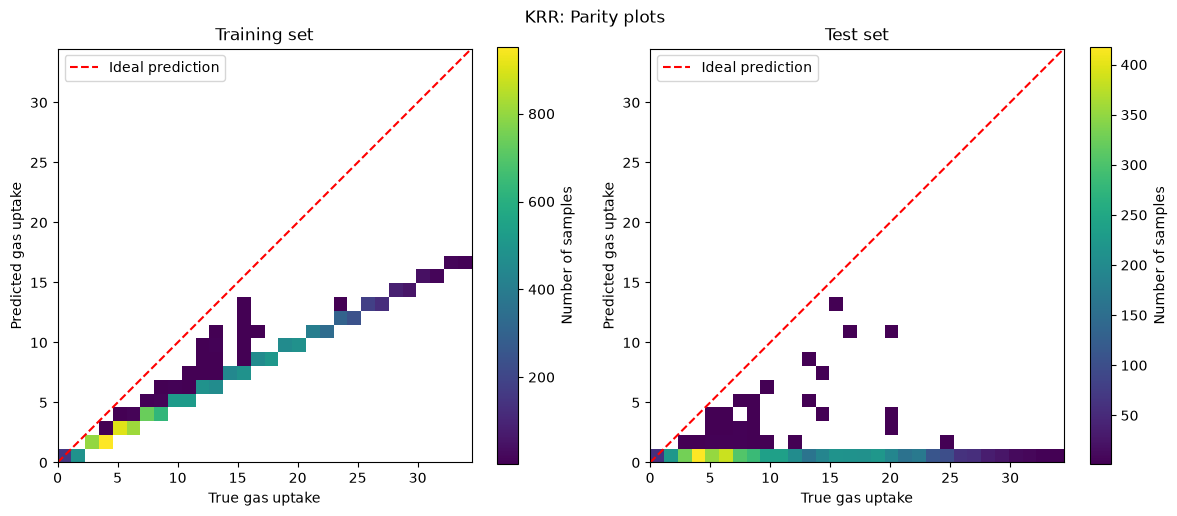

In [50]:
# plot it
def plot_parity(res_train, res_test, title='Model'):

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    all_values = np.concatenate([
        res_train['y true'], res_train['y pred'],
        res_test['y true'], res_test['y pred']
    ])

    lims = [all_values.min(), all_values.max()]

    for ax, res, label in zip(
        axes,
        [res_train, res_test],
        ['Training set', 'Test set']
    ):

        h = ax.hist2d(
            res['y true'],
            res['y pred'],
            bins=30,
            range=[lims, lims],
            cmap='viridis',
            cmin=1
        )

        ax.plot(lims, lims, 'r--', label='Ideal prediction')
        ax.set_xlim(lims)
        ax.set_ylim(lims)
        ax.set_xlabel('True gas uptake')
        ax.set_ylabel('Predicted gas uptake')
        ax.set_title(label)
        ax.legend()
        ax.set_aspect('equal')

        fig.colorbar(h[3], ax=ax, label='Number of samples')

    fig.suptitle(f'{title}: Parity plots')
    plt.tight_layout()
    plt.show()


plot_parity(res_train, res_test, title='KRR')

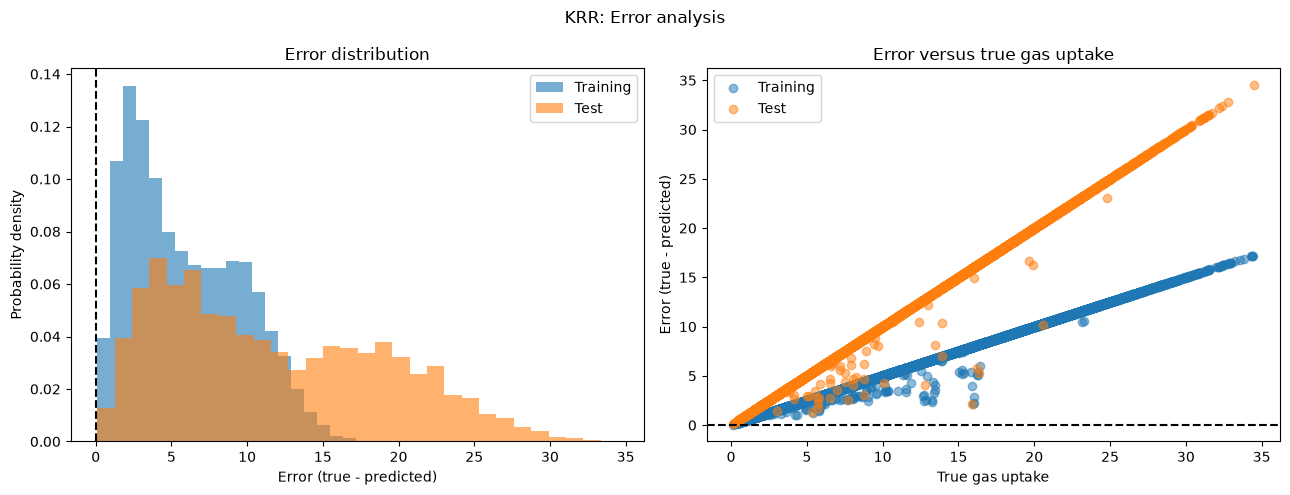

In [51]:
def plot_errors(res_train, res_test, title='Model'):

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Histogram of errors
    axes[0].hist(
        res_train['error'],
        bins=20,
        alpha=0.6,
        label='Training',
        density=True
    )

    axes[0].hist(
        res_test['error'],
        bins=30,
        alpha=0.6,
        label='Test',
        density=True
    )

    axes[0].axvline(0, color='black', linestyle='--')
    axes[0].set_xlabel('Error (true - predicted)')
    axes[0].set_ylabel('Probability density')
    axes[0].set_title('Error distribution')
    axes[0].legend()

    # Error as a function of true value
    axes[1].scatter(
        res_train['y true'],
        res_train['error'],
        alpha=0.5,
        label='Training'
    )

    axes[1].scatter(
        res_test['y true'],
        res_test['error'],
        alpha=0.5,
        label='Test'
    )

    axes[1].axhline(0, color='black', linestyle='--')
    axes[1].set_xlabel('True gas uptake')
    axes[1].set_ylabel('Error (true - predicted)')
    axes[1].set_title('Error versus true gas uptake')
    axes[1].legend()

    fig.suptitle(f'{title}: Error analysis')
    plt.tight_layout()
    plt.show()


plot_errors(res_train, res_test, title='KRR')

**6.3)** From the parity plots, especially for the test sample, we see that the model systematically underpredicts the materials with a higher gas uptake. The results get below the 1:1 line the farther the true gas uptake increases. Moreover, we see that the error gets larger with the true gas uptake. This means that we cannot use it to screen promising materials properly yet. 

**6.4)** Plotting the dummy model parity plots:

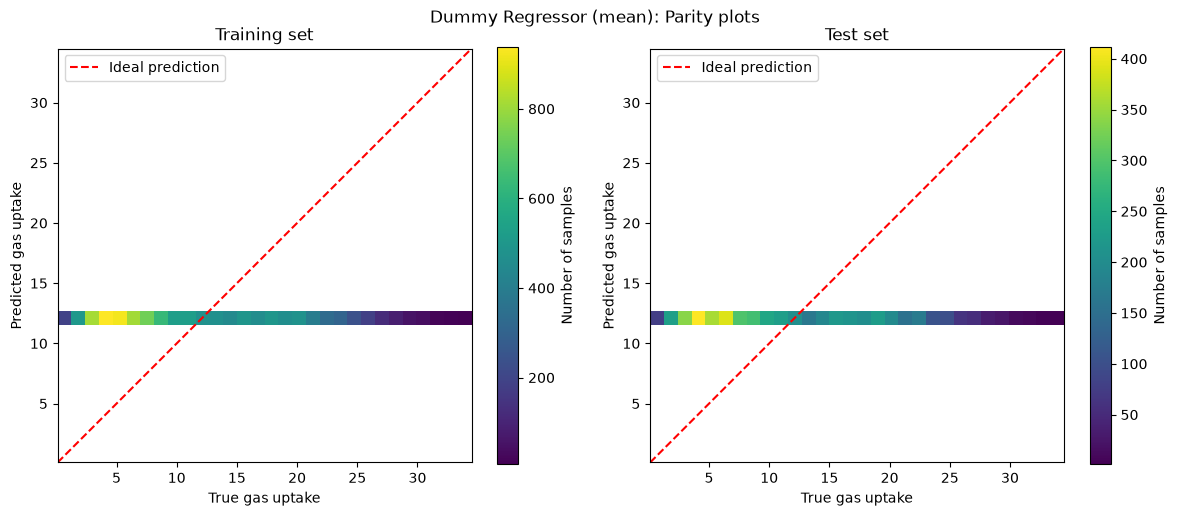

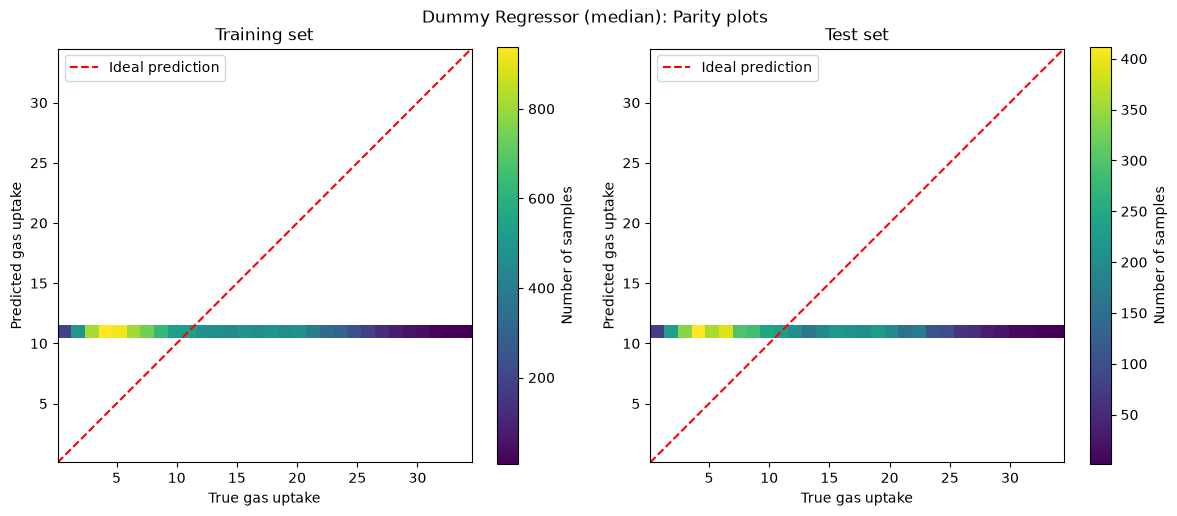

In [52]:
res_train_dummy_mean = {
    'y true': df_train_stratified[TARGET],
    'y pred': dummyregressor_mean.predict(df_train_stratified[FEATURES])
}

res_test_dummy_mean = {
    'y true': df_test_stratified[TARGET],
    'y pred': dummyregressor_mean.predict(df_test_stratified[FEATURES])
}

res_train_dummy_median = {
    'y true': df_train_stratified[TARGET],
    'y pred': dummyregressor_median.predict(df_train_stratified[FEATURES])
}

res_test_dummy_median = {
    'y true': df_test_stratified[TARGET],
    'y pred': dummyregressor_median.predict(df_test_stratified[FEATURES])
}

plot_parity(res_train_dummy_mean, res_test_dummy_mean, title='Dummy Regressor (mean)')
plot_parity(res_train_dummy_median, res_test_dummy_median, title='Dummy Regressor (median)')

The graphs make sense: the dummy models always predict the mean and median and are almost identical, as discussed in section 4. They do not reflect the actual properties of the data. Compared to the dummies, the krr model actually does change the prediction along the samples, but still struggles a lot with accuracy.

## 7. Improve the model 

Our training set still has a couple of issues you might have noticed:
- The feature values are not scaled (different features are measured in different units ...)
- Some features are basically constant, i.e. do not contain relevant information and just increase the dimensionality of the problem 
- Some feature distributions are skewed (which is more relevant for some models than for others ...)

$\color{DarkBlue}{\textsf{Short Question}}$
- Why might the scaling of the features be relevant for a machine learning model? 

**7.0.1)** Machine learning models can be sensitive to the different magnitudes of the features used to train. For example if one feature's units are on very large orders and the other feature's units don't, the feature with larger values can overpower the other one. This arises due to the algorithms often measuring the distances between the points, including the KRR.

### 7.1. Standard scaling and building a first pipeline 

Given that we will now go beyond training a single model, we will build [Pipelines](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html), which are objects that can collect a selection of transformations and estimators. This makes it quite easy to apply the same set of operations to different datasets. A simple pipeline might be built as follows 

<img src="https://vitalflux.com/wp-content/uploads/2020/08/ML-Pipeline-Page-2-1024x307.png" alt="Pipeline" width="800"/>



 $\color{DarkBlue}{\textsf{Short Exercise}}$
- Build a pipeline that first performs standard scaling and then fits a KRR. Call it `pipe_w_scaling`. 
- Fit it on the training set 
- Make predictions, calculate the errors and make the parity plots

<details>
<summary> <font color='green'>Click here for hints</font></summary>
<ul>
    <li> the <code>fit</code>, <code>predict</code> methods also work for pipelines </li>
</ul>
</details>

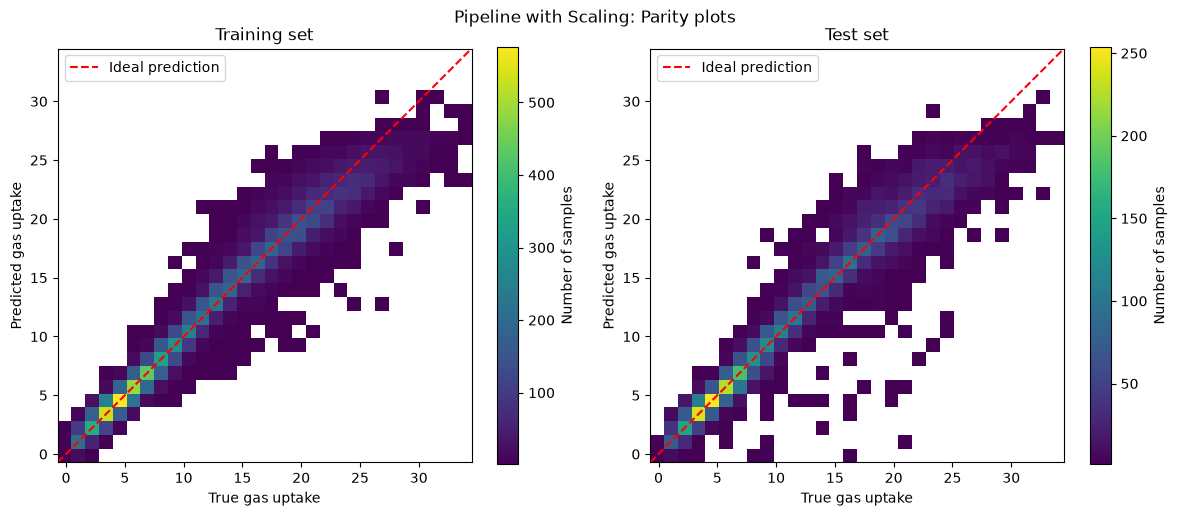

In [57]:
pipe_w_scaling = Pipeline(
   [
       ('scaling', StandardScaler()),
       ('krr', KernelRidge(kernel='rbf'))
   ]
)

pipe_w_scaling.fit(df_train_stratified[FEATURES], df_train_stratified[TARGET])

res_train_pipe_w_scaling = {
    'y true': df_train_stratified[TARGET],
    'y pred': pipe_w_scaling.predict(df_train_stratified[FEATURES])
}

res_test_pipe_w_scaling = {
    'y true': df_test_stratified[TARGET],
    'y pred': pipe_w_scaling.predict(df_test_stratified[FEATURES])
}

plot_parity(res_train_pipe_w_scaling, res_test_pipe_w_scaling, title='Pipeline with Scaling')

### 7.2. Hyperparameter optimization

A key component we did not optimize so far are hyperparameters. Those are parameters of the model that we usually cannot learn from the data but have to fix before we train the model. 
Since we cannot learn those parameters it is not trivial to select them. Hence, what we typically do in practice is to create another set, a "validation set", and use it to test models trained with different hyperparameters.

The most common approach to hyperparameter optimization is to define a grid of all relevant parameters and to search over the grid for the best model performance.

$\color{DarkBlue}{\textsf{Short Exercise}}$
- Think about which parameters you could optimize in the pipeline. Note that your KRR model has two parameters you can optimize. You can also switch off some steps by setting them to `None'.
- For each parameter you need to define a resonable grid to search over.
- Recall, what k-fold cross-validation does. Run the hyperparameter optimization using 5-fold cross-validation (you can adjust the number of folds according to your computational resources/impatience. It turns out at k=10 is the [best tradeoff between variance and bias](https://arxiv.org/abs/1811.12808)). 
Tune the hyperparameters until you are statisfied (e.g., until you cannot improve the cross validated error any more)
- Why don't we use the test set for hyperparameter tuning but instead test on the validation set? 
- Evaluate the model performance by calculating the performance metrics (MAE, MSE, max error) on the training and the test set.
- *Optional:* Instead of grid search, try to use random search on the same grid (`RandomizedSearchCV`) and fix the number of evaluations (`n_iter`) to a fraction of the number of evaluations of grid search. What do you observe and conclude?

 $\color{DarkRed}{\textsf{Tips}}$
- If you want to see what is happening, set the `verbosity` argument of the `GridSearchCV` object to a higher number.
 
- If you want to speed up the optimization, you can run it in parallel by setting the `n_jobs` argument to the number of workers. If you set it to -1 it will use all available cores. *Using all cores might freeze your computer if you do not have enough memory*
 
- If the optimization is too slow, reduce the number of data points in your set, the number of folds or the grid size. Note that it can also be a feasible strategy to first use a coarser grid and the a finer grid for fine-tuning.

- For grid search, you need to define a parameter grid, which is a dictionary of the following form: 
```(python)
param_grid = {
                    'pipelinestage__parameter': np.logspace(-4,1,10),
                    'pipelinestage': [None, TransformerA(), TransformerB()]
            }
```

- After the search, you can access the best model with `.best_estimator_` and the best parameters with `.best_params_` on the GridSearchCV instance. For example `grid_krr.best_estimator_`

- If you initialize the GridSearchCV instance with `refit=True` it will automatically train the model with all training data (and not only the training folds from cross-validations)

The double underscore (dunder) notation works recursively and specifies the parameters for any pipeline stage. 
For example, `ovasvm__estimator__cls__C` would specifiy the `C` parameter of the estimator in the one-versus-rest classifier `ovasvm`. 

You can print all parameters of the pipeline using `print(sorted(pipeline.get_params().keys()))`

<div class="alert alert-block alert-warning">
Be aware that tight grids will drastically increase the number of experiments you will run! In some cases, it can be useful to perform the optimization in steps, i.e., first use a coarse grid and then refine in interesting regions. 
Alternatively, there are approached like <a href="https://www.jmlr.org/papers/volume18/16-558/16-558.pdf"> hyperband <a> that dynamically adjust the number of data points.
</div>

<details>
<summary> <font color='green'>Click here for hints about pipelines and grid search</font></summary>
<ul>
    <li> You can use the <code>np.logspace</code> function to generate a grid for values that you want to vary on a logarithmic scale </li>
    <li> There are two hyperparameters for KRR: the regularization strength <code>alpha</code> and the Gaussian width  <code>gamma</code> </li>
    <li> For the regularization strength, values between 1 and 1e-3 can be reasonable. For gamma you can use the median heuristic, gamma = 1 / median, or values between 1e-3 and 1e3</li>
</ul>
</details>

In [42]:
print(sorted(pipe_w_scaling.get_params().keys()))

['krr', 'krr__alpha', 'krr__coef0', 'krr__degree', 'krr__gamma', 'krr__kernel', 'krr__kernel_params', 'memory', 'scaling', 'scaling__copy', 'scaling__with_mean', 'scaling__with_std', 'steps', 'transform_input', 'verbose']


In [ ]:
# Define the parameter grid and the grid search object
param_grid = {
                    'scaling': [MinMaxScaler()], # test different scaling methods
                    'krr__alpha': np.logspace(-3, -1, 5),
                    'krr__gamma': np.logspace(-1, 0.4, 5)
            }

grid_krr = GridSearchCV(pipe_w_scaling, param_grid=param_grid,
                        cv=5, verbose=2, n_jobs=2)


# optional random search
#random_krr = RandomizedSearchCV(#your pipeline, param_distributions=param_grid, n_iter=#number of evaluations,
#                        cv=#number of folds, verbose=2, n_jobs=2
#)

In [44]:
# run the grid search by calling the fit method
grid_krr.fit(df_train_stratified[FEATURES], df_train_stratified[TARGET])
print("Best parameters found: ", grid_krr.best_params_)
# optional random search
# random_krr.fit(#fillme)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best parameters found:  {'krr__alpha': np.float64(0.001), 'krr__gamma': np.float64(0.22387211385683395), 'scaling': MinMaxScaler()}


In [45]:
# get the performance metrics
best_estimator = grid_krr.best_estimator_

print("Train Metrics:", get_regression_metrics(best_estimator, df_train_stratified[FEATURES], df_train_stratified[TARGET]))
print("Test Metrics:", get_regression_metrics(best_estimator, df_test_stratified[FEATURES], df_test_stratified[TARGET]))

Train Metrics: {'mae': 0.519693491672102, 'mse': 0.5853207038005082, 'max_error': 5.882192507872865}
Test Metrics: {'mae': 0.6747126852270656, 'mse': 1.05524694005434, 'max_error': 8.806539710689417}


In [ ]:
#save parameters and model to compare
print("Best CV MAE:", -grid_krr.best_score_)
print("Best parameters:", grid_krr.best_params_)

Best CV MAE: -0.9793675579694776
Best parameters: {'krr__alpha': np.float64(0.001), 'krr__gamma': np.float64(0.22387211385683395), 'scaling': MinMaxScaler()}


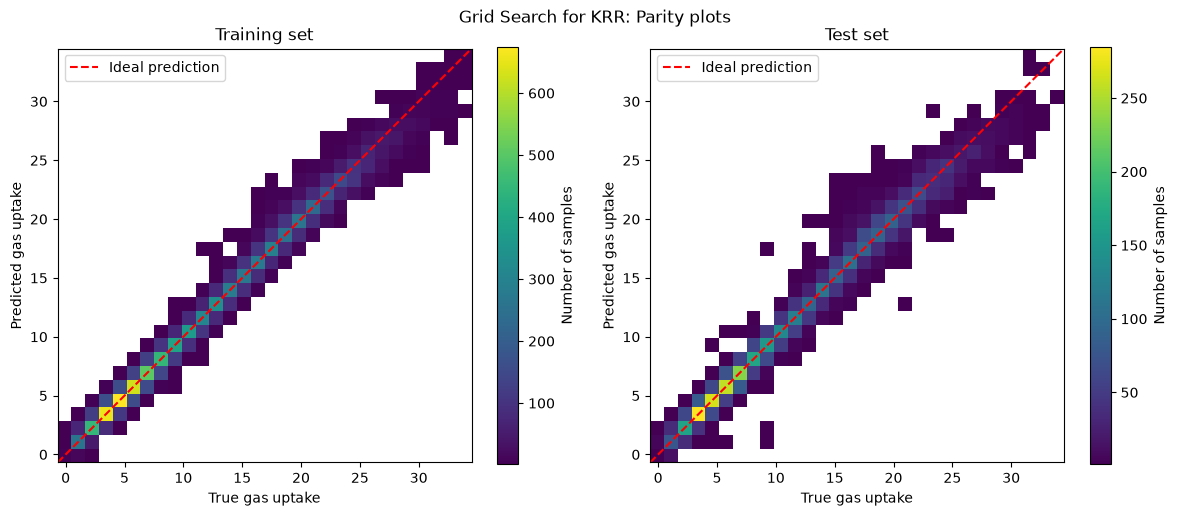

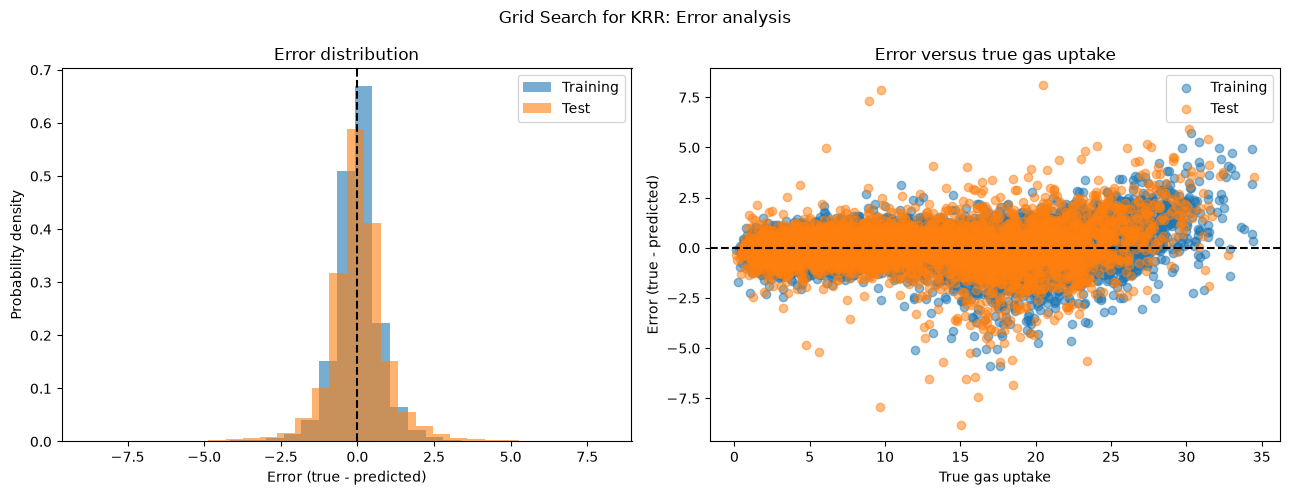

In [ ]:
#analyse parity and errors for the best estimator
res_train_grid_krr = {
    'y true': df_train_stratified[TARGET],
    'y pred': best_estimator.predict(df_train_stratified[FEATURES])
}

res_test_grid_krr = {
    'y true': df_test_stratified[TARGET],
    'y pred': best_estimator.predict(df_test_stratified[FEATURES])
}

res_train_grid_krr["error"] = res_train_grid_krr["y true"] - res_train_grid_krr["y pred"]
res_test_grid_krr["error"] = res_test_grid_krr["y true"] - res_test_grid_krr["y pred"]

plot_parity(res_train_grid_krr, res_test_grid_krr, title='Grid Search for KRR')
plot_errors(res_train_grid_krr, res_test_grid_krr, title='Grid Search for KRR')

After several cross-validations, we see that the model has noticeably narrowed onto the 1:1 line, and the errors are now much lower than the dummy models.

**7.2.4)** We cannot use the test data set to perform the tuning because of the data leakage: if we use it, we are indirectly tuning our model to be the best at predicting this specific test set, and it becomes biased.

<details>
<summary> <font color='green'>Click here for some more information about hyperparameter optimization</font></summary>
Grid search is not the most efficient way to perform hyperparamter optimization. Even <a href="http://jmlr.csail.mit.edu/papers/volume13/bergstra12a/bergstra12a.pdf">random search was shown to be more efficient</a>. Really efficient though are Bayesian optimization approaches like <a href='https://papers.nips.cc/paper/4443-algorithms-for-hyper-parameter-optimization.pdf)'>TPE</a>. This is implemented in the hyperopt library, which is also installed in your conda environment.
</details>

<details>
<summary> <font color='green'>Click here for hyperparameter optimization with hyperopt (advanded and optional outlook)</font></summary>
    
<b>Import the tools we need</b>
<code>
from hyperopt import fmin, tpe, hp, STATUS_OK, Trials, mix, rand, anneal, space_eval
from functools import partial
</code>    

<b>Define the grid</b>
<code>
param_hyperopt = {
    "krr__alpha": hp.loguniform("krr__alpha", np.log(0.001), np.log(10)),
    "krr__gamma": hp.loguniform("krr__gamma", np.log(0.001), np.log(10)),
}
</code> 

<b>Define the objective function</b>
<code>
def objective_function(params):
    pipe.set_params(
        **{
            "krr__alpha": params["krr__alpha"],
            "krr__gamma": params["krr__gamma"],
        }
    )
    score = cross_val_score(
        pipe, X_train, y_train, cv=10, scoring="neg_mean_absolute_error"
    ).mean()
    return {"loss": -score, "status": STATUS_OK} 
</code>

<b>We will use a search in which we mix random search, annealing and tpe</b>
<code>
trials = Trials()
mix_search = partial(
   mix.suggest,
   p_suggest=[(0.15, rand.suggest), (0.15, anneal.suggest), (0.7, tpe.suggest)],
)
</code>

<b>Now, we can minimize the objective function.</b>
<code>
best_param = fmin(
        objective_function,
        param_hyperopt,
        algo=mix_search,
        max_evals=MAX_EVALES,
        trials=trials,
        rstate=np.random.RandomState(RANDOM_SEED),
    )
</code>

</details>

## 8. Feature Engineering 

Finally, we would like to remove features with low variance. This can be done by setting a variance threshold.

$\color{DarkBlue}{\textsf{Short Question}}$
    
- What is the reasoning behind doing this? 
- When might it go wrong and why?

15.1) A feature with (almost) no variance has nearly the same value for every material, so it cannot help to tell the materials apart and carries no useful information. Removing such features reduces the dimensionality, makes training cheaper, and removes noise. This matters for KRR in particular, because in the RBF kernel every feature contributes equally to the distance between two materials, so uninformative features only dilute the distances. The variance threshold is unsupervised (it never looks at the target), and inside the pipeline it is fitted on the training folds only, so it causes no information leakage.

15.2) Variance is not the same as information. It depends on the units and scale of a feature: on unscaled data, a feature with a small numeric range can be removed even though it is highly predictive, while a high-variance feature can be pure noise. This is why the threshold comes before the scaler in our pipeline (after standard scaling every feature has variance 1, so the threshold would remove nothing). A nearly constant feature can also be exactly the one that explains a few special materials (# a rare metal or functional group), and it would be lost. Finally, the threshold only looks at each feature on its own, so it does not remove redundant, correlated features. Because the threshold is a hyperparameter, we tune it with cross-validation instead of fixing it by hand.

 $\color{DarkBlue}{\textsf{Short Exercise}}$
- Add a variance threshold to the pipeline (select the correct function argument)
- Use random search for hyperparameter optimization, retrain the pipeline, and calculate the performance metrics (max error, MAE, MSE) on the training and test set

In [13]:
# Define the pipeline
pipe_variance_threshold = Pipeline(
    # fillme with the pipeline steps
    [
        ('variance_treshold', VarianceThreshold(threshold=0.0)),
        ('scaling', StandardScaler()),
        ('krr', KernelRidge(kernel='rbf'))
    ]
)

In [14]:
param_grid_variance_threshold = {
                    'scaling': [MinMaxScaler(), StandardScaler()],
                    'krr__alpha': np.logspace(-5, -1, 9),
                    'krr__gamma': np.logspace(-1.5, 0.5, 9),
                    'variance_treshold__threshold': [0.0, 1e-6, 1e-4, 1e-2, 1e-1]
            }

random_variance_treshold = RandomizedSearchCV(pipe_variance_threshold, param_distributions=param_grid_variance_threshold, n_iter=8,
                        cv=3, verbose=2, n_jobs=2, random_state=RANDOM_SEED)

In [15]:
# Fit the pipeline and run the evaluation
random_variance_treshold.fit(df_train_stratified[FEATURES], df_train_stratified[TARGET])

print("Best parameters:", random_variance_treshold.best_params_)
best_vt = random_variance_treshold.best_estimator_
print("Train Metrics:", get_regression_metrics(best_vt, df_train_stratified[FEATURES], df_train_stratified[TARGET]))
print("Test Metrics:", get_regression_metrics(best_vt, df_test_stratified[FEATURES], df_test_stratified[TARGET]))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'variance_treshold__threshold': 0.0, 'scaling': MinMaxScaler(), 'krr__gamma': np.float64(0.1), 'krr__alpha': np.float64(0.0001)}
Train Metrics: {'mae': 0.5137433004738077, 'mse': 0.562122195868026, 'max_error': 5.552153564908103}
Test Metrics: {'mae': 0.6874403490087824, 'mse': 1.2252650019350093, 'max_error': 17.792741634326344}
[CV] END krr__alpha=3.1622776601683795e-05, krr__gamma=3.1622776601683795, scaling=StandardScaler(), variance_treshold__threshold=1e-06; total time=  15.5s
[CV] END krr__alpha=3.1622776601683795e-05, krr__gamma=3.1622776601683795, scaling=StandardScaler(), variance_treshold__threshold=1e-06; total time=  11.4s
[CV] END krr__alpha=0.0001, krr__gamma=0.1778279410038923, scaling=StandardScaler(), variance_treshold__threshold=0.0001; total time=   7.1s
[CV] END krr__alpha=0.0001, krr__gamma=0.1778279410038923, scaling=StandardScaler(), variance_treshold__threshold=0.0001; total time=   4

The random search tried 8 candidates with 3-fold cross-validation. The best pipeline used:
- variance threshold = 0.0 (this only removes constant features)
- MinMaxScaler
- $\alpha = 10^{-4}$, $\gamma = 0.1$

|       | MAE   | MSE   | Max error |
|-------|-------|-------|-----------|
| Train | 0.514 | 0.562 | 5.55      |
| Test  | 0.687 | 1.225 | 17.8      |

Comparison with the grid search from 7.2: (test MAE 0.675, MSE 1.055, max error 8.8): the training errors are slightly lower here, but the test errors are slightly higher. The smaller $\alpha$ probably makes the model fit the training data a bit too closely (slight overfitting).

Conclusion: removing low-variance features did not help. The search chose the threshold that removes only constant features, so no feature selection was actually used. We therefore keep the model from 7.2 as our final model.

$\color{DarkBlue}{\textsf{Short Exercise (optional)}}$
- replace the variance threshold with a model-based feature selection 
`('feature_selection', SelectFromModel(LinearSVC(penalty="l1")))` or [any feature selection method that you would like to try](https://scikit-learn.org/stable/modules/feature_selection.html)

## 9. Saving the model

Now, that we spent so much time in optimizing our model, we do not want to lose it. 

 $\color{DarkBlue}{\textsf{Short Exercise}}$
- use the [joblib library](https://scikit-learn.org/stable/modules/model_persistence.html) to save your model
- make sure you can load it again


In [18]:
# Dump your model
model = best_estimator
filename = 'krr_model.joblib'
joblib.dump(model, filename)

['krr_model.joblib']

In [17]:
# Try to load it again
model_loaded = joblib.load(filename)

In [19]:
np.allclose(model.predict(df_test_stratified[FEATURES]), model_loaded.predict(df_test_stratified[FEATURES]))

True

## 10. Influence of Regularization

 $\color{DarkBlue}{\textsf{Short Exercise}}$
- what happens if you set $\alpha$  to a really small or to large value? Why is this the case explain what the parameter means using the equation derived in the lectures?

 To test this, fix this value in one of your pipelines, retrain the models (re-optimizing the other hyperparameters) and rerun the performance evaluation.

<details>
<summary> <font color='green'>Click here for hints</font></summary>
<ul>
    <li> Check the derivation for ridge regression and KRR in the notes. </li>
    <li> Also remember the loss landscapes we discussed in the lectures about LASSO. </li>
</ul>
</details>

In [20]:
best_gamma = best_estimator.get_params()['krr__gamma']

for alpha in [1e-8, 1e3]:
    pipe_alpha = Pipeline([
        ('scaling', MinMaxScaler()),
        ('krr', KernelRidge(kernel='rbf', alpha=alpha, gamma=best_gamma))
    ])
    pipe_alpha.fit(df_train_stratified[FEATURES], df_train_stratified[TARGET])
    print("alpha =", alpha)
    print(" train:", get_regression_metrics(pipe_alpha, df_train_stratified[FEATURES], df_train_stratified[TARGET]))
    print(" test: ", get_regression_metrics(pipe_alpha, df_test_stratified[FEATURES], df_test_stratified[TARGET]))

alpha = 1e-08
 train: {'mae': 0.056790124291185747, 'mse': 0.012558699494957443, 'max_error': 1.2127201297218644}
 test:  {'mae': 2.9529456453353213, 'mse': 74.26985110466184, 'max_error': 206.5907947266107}
alpha = 1000.0
 train: {'mae': 3.750337824890808, 'mse': 27.298062005736767, 'max_error': 26.495614759940487}
 test:  {'mae': 3.6836665971923086, 'mse': 26.156544228453463, 'max_error': 26.795454371718726}


19.1) Effect of $\alpha$

KRR minimizes $\lVert y - Kc\rVert^2 + \alpha\, c^\top K c$, which gives the weights $c = (K + \alpha I)^{-1} y$ and the predictions $f(x)=\sum_i c_i\,k(x,x_i)$. The parameter $\alpha$ sets the trade-off between fitting the training data and keeping the function smooth (small weights). It is the L2 penalty of ridge regression.

I fixed $\gamma$ and the MinMaxScaler from 7.2 and changed only $\alpha$ (the other hyperparameters were not re-optimized, to keep the effect of $\alpha$ isolated):

| $\alpha$ | Train MAE | Train MSE | Test MAE | Test MSE | Test max error |
|---|---|---|---|---|---|
| $10^{-8}$ (very small) | 0.057 | 0.013 | 2.95 | 74.3 | 206.6 |
| $10^{-3}$ (best, from 7.2) | 0.520 | 0.585 | 0.675 | 1.055 | 8.81 |
| $10^{3}$ (very large) | 3.75 | 27.3 | 3.68 | 26.2 | 26.8 |

Very small $\alpha$ (overfitting, high variance): For $\alpha \to 0$, $(K+\alpha I)^{-1} \to K^{-1}$ and the model interpolates the training data exactly: the training MSE is almost 0 (0.013). The weights are then very large and unstable, because $K$ is nearly singular and the tiny eigenvalues amplify the noise. The model fails on new materials: the test MSE is 74 and the largest test error is 207 mmol/g, a physically absurd prediction.

Very large $\alpha$ (underfitting, high bias): In the eigenbasis of $K$ the training predictions are $\hat y = \sum_i \frac{\lambda_i}{\lambda_i+\alpha}(u_i^\top y)\,u_i$. For large $\alpha$ all components with $\lambda_i \ll \alpha$ are suppressed, so only the coarsest trends remain, and for $\alpha\to\infty$ all weights go to 0 (KRR has no intercept, so the predictions go to 0). Here the model is very smooth: the training and test errors are both large (MAE about 3.7) and nearly equal, so it cannot even fit the training data.

In between, $\alpha = 10^{-3}$ balances the two: the training error is small, and the test error is only slightly larger.

Unlike LASSO, whose L1 penalty (diamond-shaped constraint region in the loss landscape) sets weights exactly to zero, the L2 penalty of ridge/KRR shrinks all weights smoothly and never makes them exactly zero.

## 11. Interpreting the model 

Now, that our model performs decently, we would like to know which features are mainly responsible for this, i.e. how the model performs its reasoning. 

One method to do so is the [permutation feature importance technique](https://christophm.github.io/interpretable-ml-book/feature-importance.html).

$\color{DarkBlue}{\textsf{Short question}}$

We use both descriptors that encode the pore geometry (density, pore diameters, surface areas) as well as some that describe the chemistry of the MOF (the RACs). 
- Would you expect the relative importance of these features to be different for prediction of gas adsorption at high vs low gas pressure?

<details>
<summary> <font color='green'>Click here for a hint</font></summary>
<ul>
    <li> <a href="https://pubs.acs.org/doi/abs/10.1021/acs.chemmater.8b02257">An article from Diego et al.</a> (10.1021/acs.chemmater.8b02257) gives some hints.</li>
</ul>
</details>

20.1) Yes. At high pressure the uptake is limited by capacity (how much space and surface is available per gram), so the geometric descriptors (density, pore diameters, surface area) should dominate. At low pressure only the strongest binding sites are filled, so the uptake depends on how strongly CO$_2$ binds there, and the chemistry (RACs: functional groups, metal centre) becomes more important.

This agrees with Diego et al. (10.1021/acs.chemmater.8b02257): in their models, structural descriptors such as pore diameter, surface area and density were the most important for absolute CO$_2$ capture metrics at 20 bar, while chemistry descriptors (most negative charge, dipole moment of the functional group) were more important for the CO$_2$:N$_2$ mixtures at 1 bar. It also fits our CH$_4$ correlations in section 3.4, where geometry mattered less at low pressure. Our target is CO$_2$ uptake at 16 bar, so it is expected geometric descriptors to dominate.

 $\color{DarkBlue}{\textsf{Short Exercise}}$
- Complete the function `_calculate_permutation_scores` (which we took from the `sklearn` package) and which is needed to calculate the permutation feature importance using the `permutation_importance` function. 

In [21]:
def _calculate_permutation_scores(estimator, X, y, col_idx, random_state,
                                  n_repeats, scorer):
    """Calculate score when `col_idx` is permuted. Based on the sklearn implementation

    estimator: sklearn estimator object
    X: pd.Dataframe or np.array
    y: pd.Dataframe or np.array
    col_idx: int
    random_state: int
    n_repeats: int
    scorer: function that takes model, X and y_true as arguments
    """
    random_state = check_random_state(random_state)

    X_permuted = X.copy()
    scores = np.zeros(n_repeats)
    # get the indices
    shuffling_idx = np.arange(X.shape[0])
    for n_round in range(n_repeats):
        # FILL BELOW HERE
        # shuffle them (fill in what you want to shuffle)
        random_state.shuffle(shuffling_idx)

        # Deal with dataframes
        if hasattr(X_permuted, "iloc"):
            # .iloc selects the indices from a dataframe and you give it [row, column]
            col = X_permuted.iloc[shuffling_idx, col_idx]
            col.index = X_permuted.index
            X_permuted.iloc[:, col_idx] = col

        # Deal with numpy arrays
        else:
            # FILL BELOW HERE
            # array indexing is [row, column]
            X_permuted[:, col_idx] = X_permuted[shuffling_idx, col_idx]

        # Get the scores
        feature_score = scorer(estimator, X_permuted, y)

        # record the scores in array
        scores[n_round] = feature_score

    return scores

Nothing to change in the function below, it just calls the `_calculate_permutation_scores` function you just completed. 

In [22]:
def permutation_importance(
    estimator,
    X,
    y,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    n_jobs=2,
    random_state=None,
):
    """Permutation importance for feature evaluation
    estimator : object
        An estimator that has already been :term:`fitted` and is compatible
        with :term:`scorer`.
    X : ndarray or DataFrame, shape (n_samples, n_features)
        Data on which permutation importance will be computed.
    y : array-like or None, shape (n_samples, ) or (n_samples, n_classes)
        Targets for supervised or `None` for unsupervised.
    scoring : string, callable or None, default=None
        Scorer to use. It can be a single
        string (see :ref:`scoring_parameter`) or a callable (see
        :ref:`scoring`). If None, the estimator's default scorer is used.
    n_repeats : int, default=5
        Number of times to permute a feature.
    n_jobs : int or None, default=2
        The number of jobs to use for the computation.
        `None` means 1 unless in a :obj:`joblib.parallel_backend` context.
        `-1` means using all processors. See :term:`Glossary <n_jobs>`
        for more details.
    random_state : int, RandomState instance, or None, default=None
        Pseudo-random number generator to control the permutations of each
        feature. See :term:`random_state`.
    """
    # Deal with dataframes
    if not hasattr(X, "iloc"):
        X = check_array(X, force_all_finite="allow-nan", dtype=None)

    # Precompute random seed from the random state to be used
    # to get a fresh independent RandomState instance for each
    # parallel call to _calculate_permutation_scores, irrespective of
    # the fact that variables are shared or not depending on the active
    # joblib backend (sequential, thread-based or process-based).
    random_state = check_random_state(random_state)
    random_seed = random_state.randint(np.iinfo(np.int32).max + 1)

    # Determine scorer from user options.
    scorer = check_scoring(estimator, scoring=scoring)
    # get the performance score on the unpermuted data
    baseline_score = scorer(estimator, X, y)

    # run the permuted evaluations in parallel for each column
    scores = Parallel(n_jobs=n_jobs)(
        delayed(_calculate_permutation_scores)(
            estimator, X, y, col_idx, random_seed, n_repeats, scorer
        )
        for col_idx in range(X.shape[1])
    )

    # get difference two
    importances = baseline_score - np.array(scores)

    # return the results (dictionary)
    return Bunch(
        importances_mean=np.mean(importances, axis=1),
        importances_std=np.std(importances, axis=1),
        importances=importances,
    )


 $\color{DarkBlue}{\textsf{Short Exercise}}$
- Use your function to find the five most important features.
- Which are they? Did you expect this result?

In [23]:
X_perm = df_test_stratified[FEATURES].sample(n=1000, random_state=RANDOM_SEED)
y_perm = df_test_stratified.loc[X_perm.index, TARGET]

permutation_results = permutation_importance(best_estimator, X_perm, y_perm, n_repeats=3, n_jobs=2, random_state=RANDOM_SEED)

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
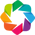

:Overlay
   .Bars.I      :Bars   [features]   (importances_mean,importances_std)
   .ErrorBars.I :ErrorBars   [features]   (importances_mean,importances_std)

In [28]:
import holoviews as hv
hv.extension("bokeh")

permutation_results["features"] = FEATURES
bars = hv.Bars(
    permutation_results, "features", ["importances_mean", "importances_std"]
).sort("importances_mean", reverse=True)
errors = hv.ErrorBars(
    permutation_results, "features", vdims=["importances_mean", "importances_std"]
).sort("importances_mean", reverse=True)

bars * errors


In [27]:
top5 = np.argsort(permutation_results.importances_mean)[-5:][::-1]
for idx in top5:
    print(FEATURES[idx], permutation_results.importances_mean[idx])


sum-f-lig-S-2 7.92663416177949
sum-f-lig-S-0 5.289550522478198
total_POV_volumetric 5.240320866930108
total_SA_volumetric 4.021256314455573
sum-f-lig-I-0 3.876692808073041


22.2) The five most important features (increase in MAE when the feature is shuffled, in mmol/g) are: sum-f-lig-S-2 (7.9), sum-f-lig-S-0 (5.3), total_POV_volumetric (5.2), total_SA_volumetric (4.0) and sum-f-lig-I-0 (3.9).

Three are linker RACs (covalent radius S and identity I, summed over the linkers) and two are geometric descriptors (volumetric pore volume and surface area). This is only partly what I expected. I expected geometry to dominate at high pressure, and pore volume and surface area are indeed in the top five, but the two most important features are linker RACs. One possible explanation is that these linker sums act as a proxy for linker size and the amount of linker material the framework contains, which relates to pore size and density, so they also carry geometric information.

<details>
<summary> <font color='green'>Click here for hints</font></summary>
<ul>
    <li> To get the top <emph>n</emph> indices of an array <code>a</code>, you can use <code>np.argsort(a)[-n:]</code></li>
    <li> Get the feature names from the <code>FEATURES</code> list </li> 
    <li> combined this might look like <code>np.array(FEATURES)[np.argsort(a)[-n:]]</code></li>
</ul>
</details>

<details>
<summary> <font color='green'>Click here for more information on model interpretation</font></summary>
The permutation feature importance technique is not a silver bullet, e.g. there are issues with correlated features.
However, it is likely <a href='https://explained.ai/rf-importance/'>a better choice than feature importance, like impurity decrease, derived from random forests</a>).
</details>